# 07 — Monte Carlo Simulation

**Goal:** simulate a distribution of future portfolio outcomes by
bootstrapping historical daily returns, and compare it against the
parametric-Normal alternative.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'BND' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'MSFT' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['BND', 'MSFT']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['SPY', 'GLD', 'AAPL']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.risk.monte_carlo import run_monte_carlo
from src.portfolio.analytics import portfolio_returns
from src.config import CONFIG

weights = pd.Series(1 / len(TICKERS), index=TICKERS)
port_returns = portfolio_returns(returns_panel, weights)

mc_empirical = run_monte_carlo(
    port_returns, number_of_simulations=10000, time_horizon_days=20,
    confidence_level=0.95, random_seed=42, distribution="empirical", initial_value=100_000,
)
mc_normal = run_monte_carlo(
    port_returns, number_of_simulations=10000, time_horizon_days=20,
    confidence_level=0.95, random_seed=42, distribution="normal", initial_value=100_000,
)

print(f"Empirical (bootstrap):  VaR=${mc_empirical.var:,.0f}  CVaR=${mc_empirical.cvar:,.0f}  P(loss)={mc_empirical.probability_of_loss:.1%}")
print(f"Normal (parametric):    VaR=${mc_normal.var:,.0f}  CVaR=${mc_normal.cvar:,.0f}  P(loss)={mc_normal.probability_of_loss:.1%}")

Empirical (bootstrap):  VaR=$4,393  CVaR=$5,726  P(loss)=41.6%
Normal (parametric):    VaR=$4,472  CVaR=$5,640  P(loss)=41.4%


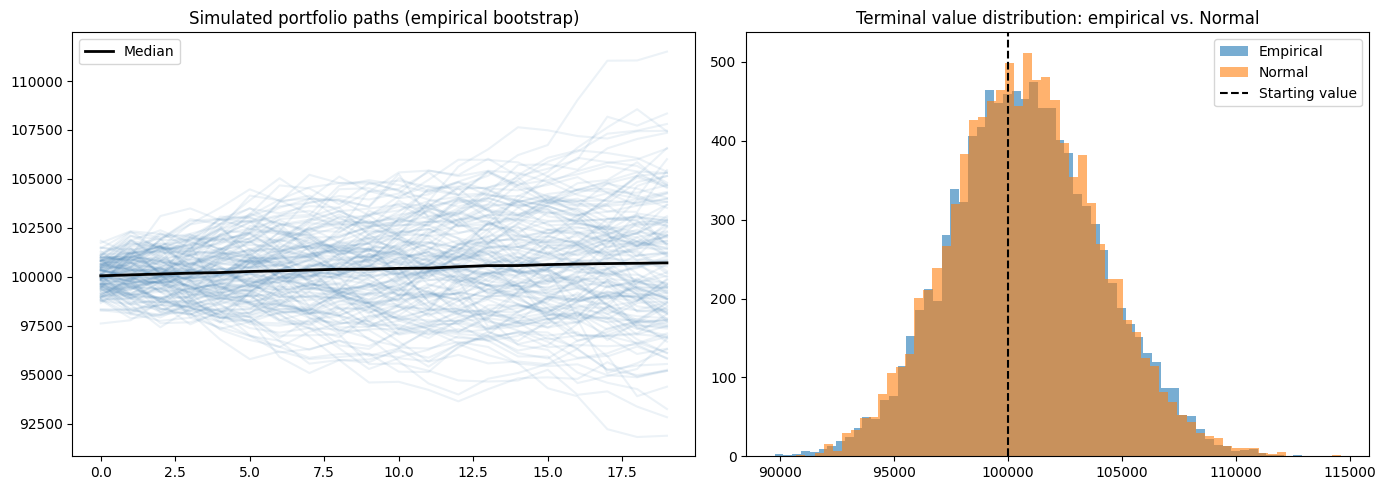

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sample_idx = np.random.default_rng(0).choice(mc_empirical.paths.shape[0], size=150, replace=False)
for i in sample_idx:
    axes[0].plot(mc_empirical.paths[i], color="steelblue", alpha=0.1)
axes[0].plot(np.median(mc_empirical.paths, axis=0), color="black", linewidth=2, label="Median")
axes[0].set_title("Simulated portfolio paths (empirical bootstrap)")
axes[0].legend()

axes[1].hist(mc_empirical.terminal_wealth, bins=60, alpha=0.6, label="Empirical")
axes[1].hist(mc_normal.terminal_wealth, bins=60, alpha=0.6, label="Normal")
axes[1].axvline(100_000, color="black", linestyle="--", label="Starting value")
axes[1].set_title("Terminal value distribution: empirical vs. Normal")
axes[1].legend()
plt.tight_layout()
plt.show()

In [4]:
pctiles = pd.DataFrame({"empirical": mc_empirical.percentiles, "normal": mc_normal.percentiles})
pctiles.round(0)

,empirical,normal
p1,93355.0,93547.0
p5,95607.0,95528.0
p25,98562.0,98543.0
p50,100707.0,100722.0
p75,102956.0,102917.0
p95,106368.0,106248.0
p99,108441.0,108722.0


## Takeaways

- The empirical (bootstrap) method captures the real historical fat tails and skew; the Normal method smooths them away, usually producing a narrower, more optimistic-looking distribution.
- All randomness is seeded (`random_seed=42`), so re-running this notebook reproduces identical numbers.
- Continue to **08 — Stress Testing** for scenario-based (not probabilistic) risk analysis.